In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [2]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)
print('Dataset loaded successfully:', filename)
df.head()

Saving student_performance.csv to student_performance.csv
Dataset loaded successfully: student_performance.csv


,Student_ID,Study_Hours,Attendance_Percent,Sleep_Hours,Assignment_Score,Final_Score
0,S001,6.49,89.11,8.68,86.68,94.87
1,S002,5.22,100.00,8.11,66.73,90.59
2,S003,6.80,61.22,7.07,62.73,80.60
3,S004,8.55,84.76,6.22,74.95,98.44
4,S005,5.03,70.19,7.84,72.45,70.29


In [3]:
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nFirst 5 rows:')
display(df.head())
print('\nLast 5 rows:')
display(df.tail())

Shape: (500, 6)

Columns: ['Student_ID', 'Study_Hours', 'Attendance_Percent', 'Sleep_Hours', 'Assignment_Score', 'Final_Score']

First 5 rows:


,Student_ID,Study_Hours,Attendance_Percent,Sleep_Hours,Assignment_Score,Final_Score
0,S001,6.49,89.11,8.68,86.68,94.87
1,S002,5.22,100.00,8.11,66.73,90.59
2,S003,6.80,61.22,7.07,62.73,80.60
3,S004,8.55,84.76,6.22,74.95,98.44
4,S005,5.03,70.19,7.84,72.45,70.29



Last 5 rows:


,Student_ID,Study_Hours,Attendance_Percent,Sleep_Hours,Assignment_Score,Final_Score
495,S496,6.58,74.63,9.41,91.05,100.00
496,S497,3.43,99.57,9.47,74.60,86.24
497,S498,5.12,85.69,8.45,61.77,85.21
498,S499,3.75,71.15,8.23,72.55,87.45
499,S500,2.73,84.87,7.71,63.83,79.85


In [4]:
print('Dataset information:')
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_ID          500 non-null    object 
 1   Study_Hours         500 non-null    float64
 2   Attendance_Percent  500 non-null    float64
 3   Sleep_Hours         500 non-null    float64
 4   Assignment_Score    500 non-null    float64
 5   Final_Score         500 non-null    float64
dtypes: float64(5), object(1)
memory usage: 23.6+ KB


In [5]:
print('Descriptive statistics:')
display(df.describe(include='all').T)

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,500,500,S500,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Study_Hours,500.0,NaN,NaN,NaN,5.50648,1.910191,1.0,4.1,5.53,6.775,10.0
Attendance_Percent,500.0,NaN,NaN,NaN,78.2356,11.416274,45.64,70.855,78.34,85.8125,100.0
Sleep_Hours,500.0,NaN,NaN,NaN,7.13172,1.204911,4.0,6.2775,7.14,7.9025,10.0
Assignment_Score,500.0,NaN,NaN,NaN,75.21792,14.16161,30.89,65.8175,74.865,85.4925,100.0
Final_Score,500.0,NaN,NaN,NaN,87.66868,10.072578,54.95,81.3825,88.685,96.385,100.0


In [6]:
print('Missing values:')
display(df.isnull().sum().to_frame('Missing_Values'))
print('Total missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Missing values:


,Missing_Values
Student_ID,0
Study_Hours,0
Attendance_Percent,0
Sleep_Hours,0
Assignment_Score,0
Final_Score,0


Total missing values: 0
Duplicate rows: 0


In [7]:
# Remove exact duplicate rows if any exist
df = df.drop_duplicates().copy()
print('Shape after duplicate removal:', df.shape)

Shape after duplicate removal: (500, 6)


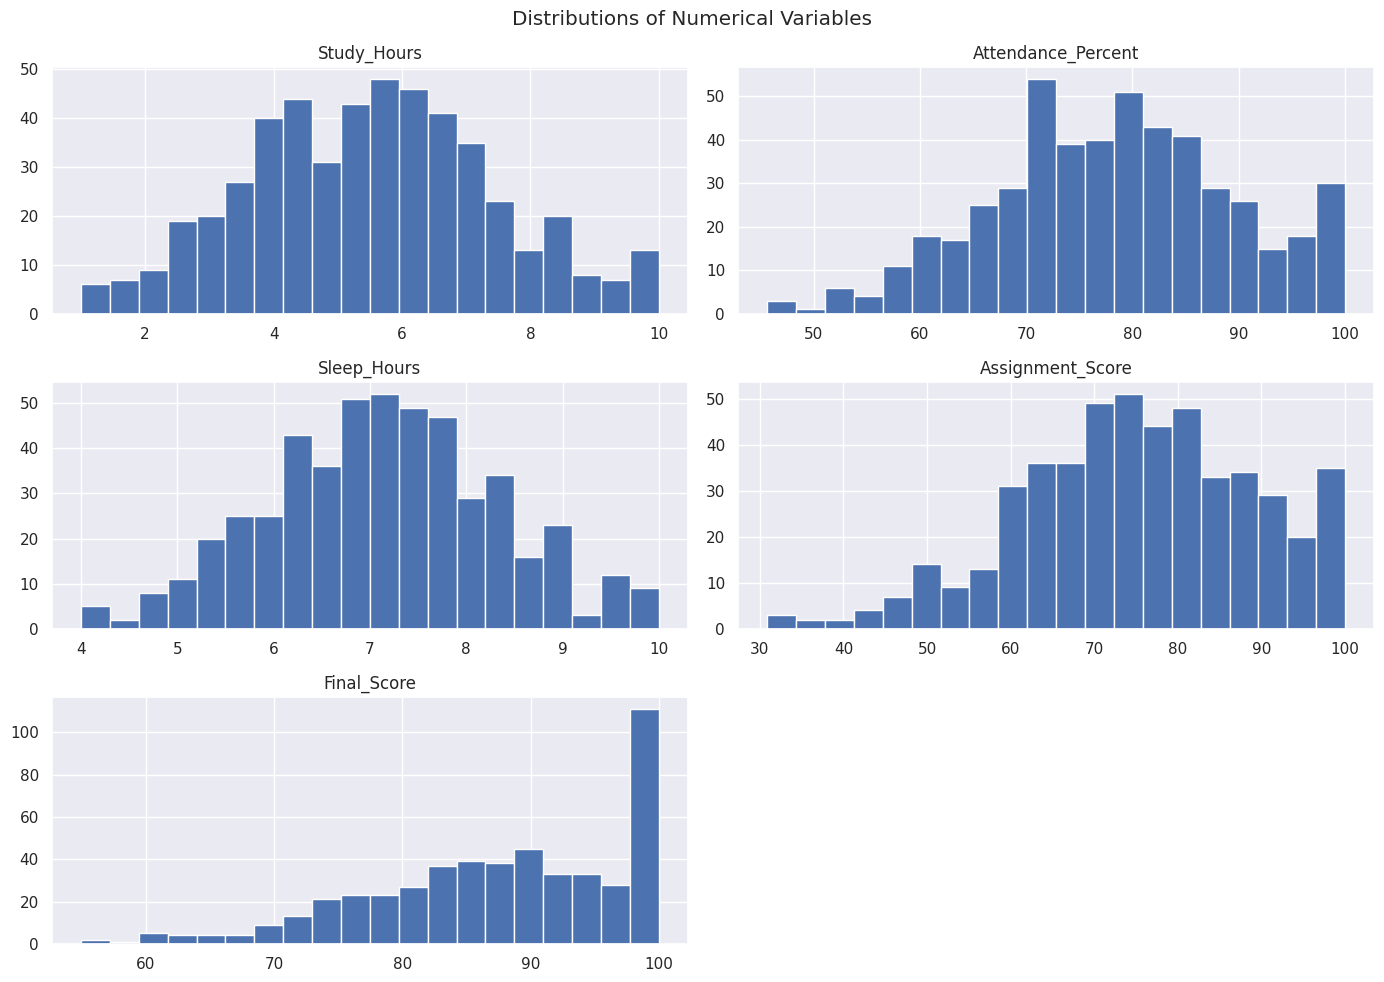

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols].hist(figsize=(14, 10), bins=20)
plt.suptitle('Distributions of Numerical Variables')
plt.tight_layout()
plt.show()

### Box Plot — Outlier Inspection

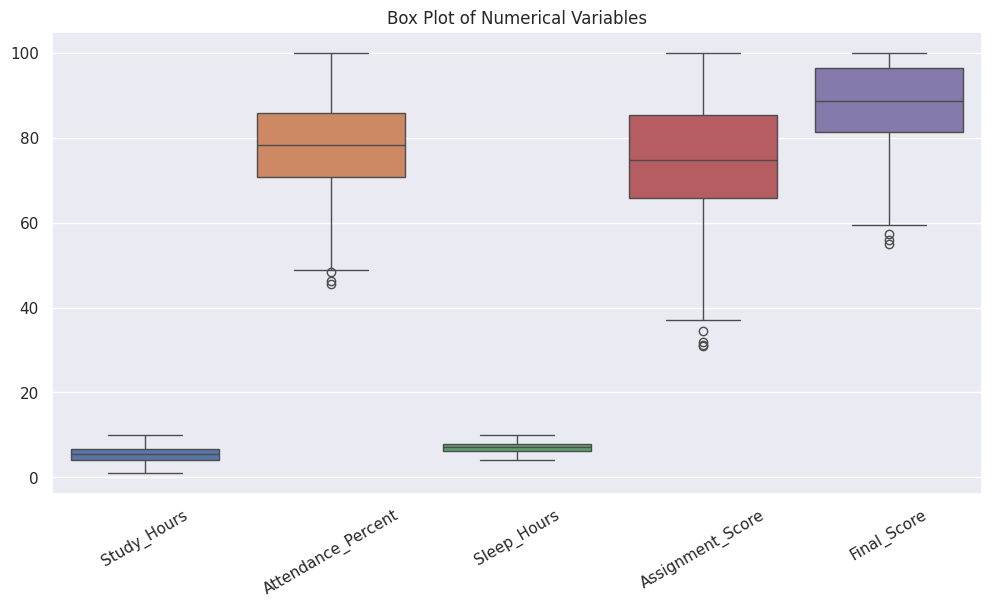

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_cols])
plt.title('Box Plot of Numerical Variables')
plt.xticks(rotation=30)
plt.show()

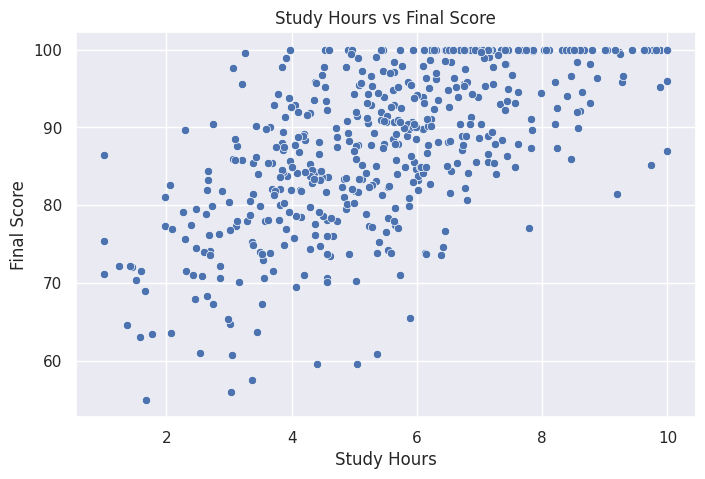

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Study_Hours', y='Final_Score')
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.show()

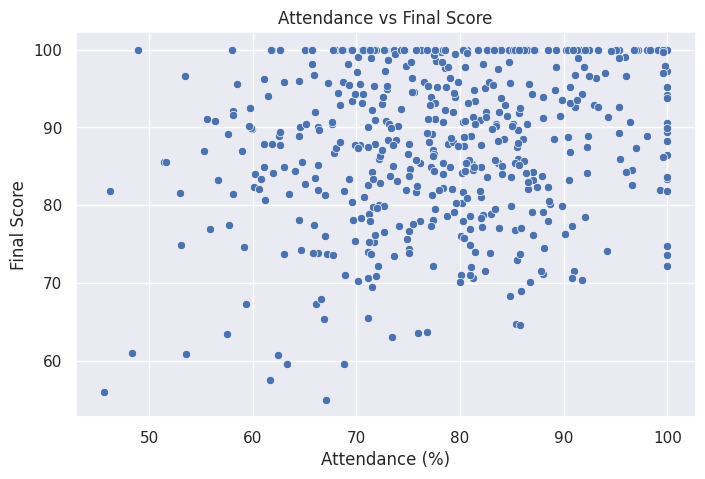

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Attendance_Percent', y='Final_Score')
plt.title('Attendance vs Final Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Final Score')
plt.show()

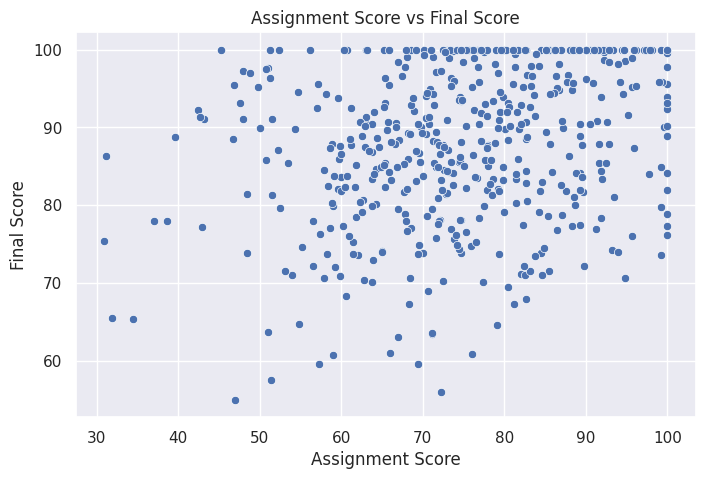

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Assignment_Score', y='Final_Score')
plt.title('Assignment Score vs Final Score')
plt.xlabel('Assignment Score')
plt.ylabel('Final Score')
plt.show()

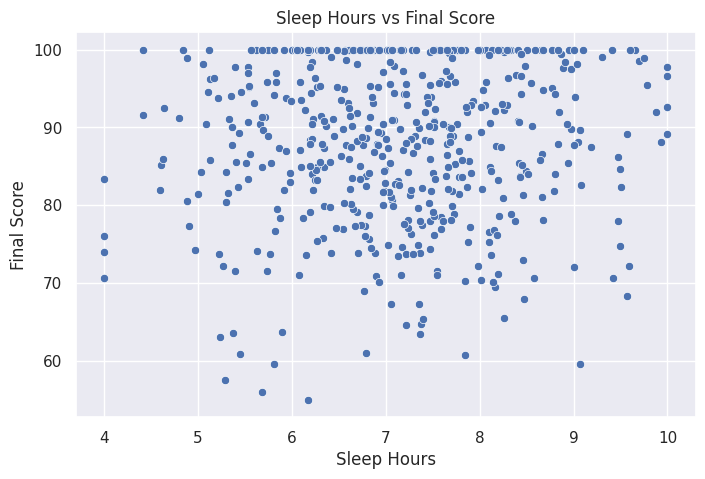

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sleep_Hours', y='Final_Score')
plt.title('Sleep Hours vs Final Score')
plt.xlabel('Sleep Hours')
plt.ylabel('Final Score')
plt.show()

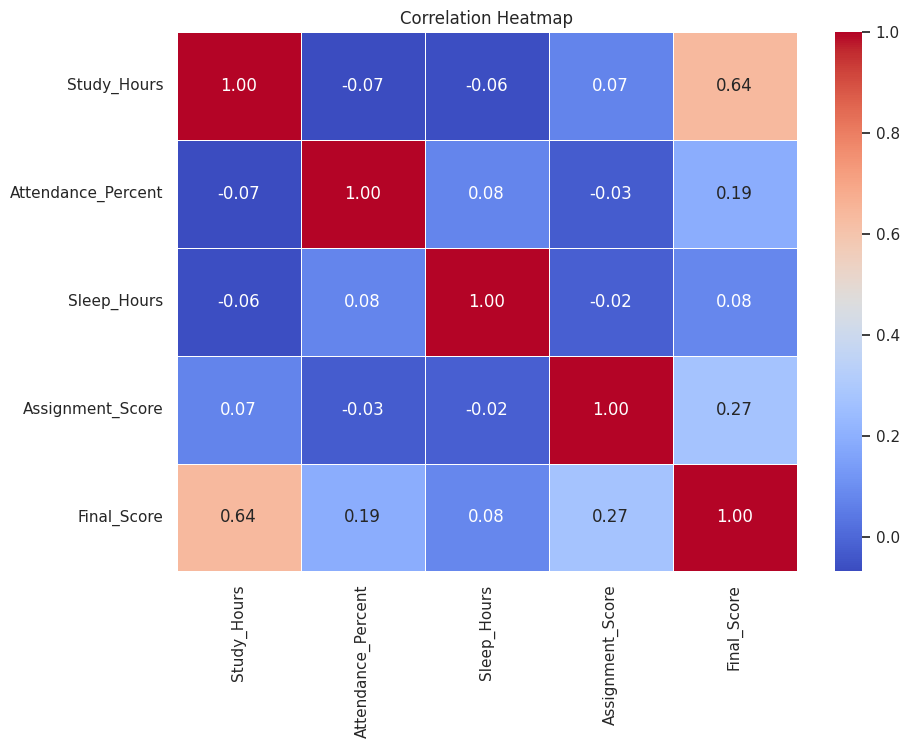

In [14]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [15]:
final_corr = corr['Final_Score'].drop('Final_Score').sort_values(ascending=False)
print('Correlation with Final Score:')
display(final_corr.to_frame('Correlation'))

Correlation with Final Score:


,Correlation
Study_Hours,0.638340
Assignment_Score,0.273377
Attendance_Percent,0.193956
Sleep_Hours,0.081024


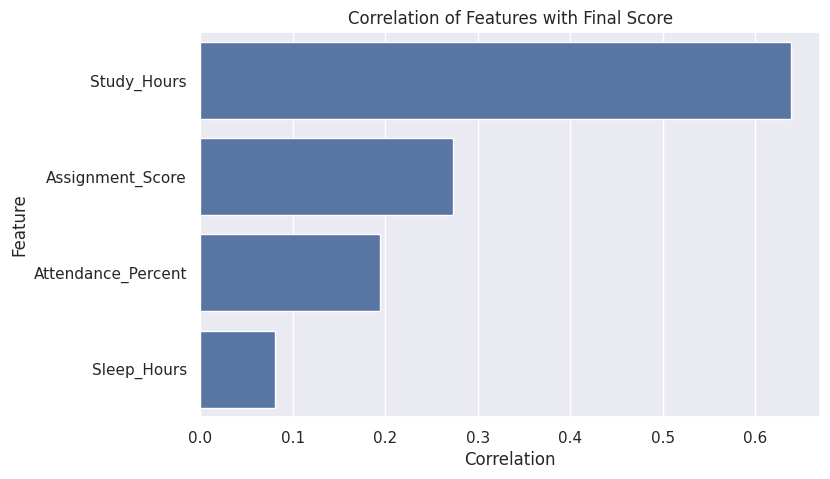

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(x=final_corr.values, y=final_corr.index)
plt.title('Correlation of Features with Final Score')
plt.xlabel('Correlation')
plt.ylabel('Feature')
plt.show()

In [17]:
print('--- EDA INSIGHTS ---')
print(f'Total records analyzed: {len(df)}')
print(f'Average Final Score: {df["Final_Score"].mean():.2f}')
print(f'Average Study Hours: {df["Study_Hours"].mean():.2f}')
print(f'Average Attendance: {df["Attendance_Percent"].mean():.2f}%')
top_feature = final_corr.index[0]
top_value = final_corr.iloc[0]
print(f'Most positively associated feature: {top_feature} ({top_value:.2f})')
print('Note: correlation indicates association, not causation.')

--- EDA INSIGHTS ---
Total records analyzed: 500
Average Final Score: 87.67
Average Study Hours: 5.51
Average Attendance: 78.24%
Most positively associated feature: Study_Hours (0.64)
Note: correlation indicates association, not causation.
